https://www.tensorflow.org/tutorials/images/classification

https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image_dataset_from_directory


In [2]:
from keras.datasets import cifar10
from keras.models import Sequential
from keras.utils import to_categorical
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
(X_train, y_train),(X_test, y_test) = cifar10.load_data()

In [3]:
X_train.shape 
#quantidade de imagens, px, px, CAMADAS RGB

(50000, 32, 32, 3)

In [4]:
X_train = X_train.astype("float32")/255.0
X_test = X_test.astype("float32")/255.0



In [5]:
y_train = to_categorical(y_train,10) # 10 = numero de classes
y_test = to_categorical(y_test,10)

In [6]:
y_train

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 0., ..., 0., 0., 1.],
       ...,
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]], shape=(50000, 10))

In [17]:
modelo = Sequential([
    Conv2D(32, (3,3), padding="same",activation="relu"),
    Conv2D(32, (3,3),activation="relu"),
    MaxPool2D(pool_size=(2,2)),
    Dropout(0.25),

    Conv2D(64, (3,3), padding="same",activation="relu"),
    Conv2D(64, (3,3),activation="relu"),
    MaxPool2D(pool_size=(2,2)),
    Dropout(0.25),

    Flatten(),
    Dense(512,activation="relu"),
    
    Dense(10,activation="softmax"),
])

modelo.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

#early_stopping = EarlyStopping(monitor="val_loss", patience=3)

history = modelo.fit(X_train, y_train,batch_size=32,epochs=100, validation_split=0.2)

Epoch 1/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 22s 17ms/step - accuracy: 0.4588 - loss: 1.4852 - val_accuracy: 0.5612 - val_loss: 1.2127
Epoch 2/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.6180 - loss: 1.0764 - val_accuracy: 0.6786 - val_loss: 0.9301
Epoch 3/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.6805 - loss: 0.9031 - val_accuracy: 0.7125 - val_loss: 0.8221
Epoch 4/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 22s 17ms/step - accuracy: 0.7286 - loss: 0.7745 - val_accuracy: 0.7298 - val_loss: 0.7740
Epoch 5/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.7563 - loss: 0.6863 - val_accuracy: 0.7475 - val_loss: 0.7477
Epoch 6/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 22s 17ms/step - accuracy: 0.7884 - loss: 0.6018 - val_accuracy: 0.7404 - val_loss: 0.7544
Epoch 7/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 0.8087 - loss: 0.5387 - val_accuracy: 0.7487 - val_loss: 0.7475
Epoch 8/100
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 21s 17ms/step - accuracy: 

In [18]:
previsoes = modelo.predict(X_test)
previsoes

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


array([[3.5483040e-13, 1.5322119e-08, 3.8041495e-08, ..., 1.2378193e-07,
        1.5699925e-07, 4.3438577e-06],
       [2.9033193e-12, 1.1435193e-13, 3.8718553e-29, ..., 5.3069559e-29,
        1.0000000e+00, 2.6141149e-16],
       [1.2684849e-01, 3.1678425e-04, 1.7610581e-08, ..., 3.6856931e-09,
        8.7245578e-01, 1.0051619e-04],
       ...,
       [5.4843501e-19, 1.1894374e-24, 4.8383558e-10, ..., 1.5256103e-10,
        1.5394352e-15, 2.7285603e-20],
       [5.3485215e-04, 9.9941134e-01, 1.1382478e-12, ..., 1.3864403e-10,
        1.2765393e-11, 2.3270706e-05],
       [0.0000000e+00, 0.0000000e+00, 0.0000000e+00, ..., 1.0000000e+00,
        0.0000000e+00, 0.0000000e+00]], shape=(10000, 10), dtype=float32)

In [19]:
previsoes_classes = np.argmax(previsoes,axis=1)
previsoes_classes

array([3, 8, 8, ..., 5, 1, 7], shape=(10000,))

In [20]:
y_test_classes = np.argmax(y_test, axis=1)
y_test_classes

array([3, 8, 8, ..., 5, 1, 7], shape=(10000,))

In [21]:
accuracy_score(y_test_classes, previsoes_classes)

0.7326

In [22]:
confusion_matrix(y_test_classes,previsoes_classes)

array([[793,  20,  28,  18,  17,   8,  12,  20,  60,  24],
       [ 10, 842,   2,  10,   7,   8,   7,   3,  20,  91],
       [ 81,   7, 525,  79,  94,  74,  87,  33,  12,   8],
       [ 22,  10,  33, 543,  67, 159,  83,  52,  12,  19],
       [ 26,   5,  36,  72, 679,  28,  59,  91,   3,   1],
       [ 15,   5,  34, 168,  44, 633,  32,  55,   3,  11],
       [  7,   4,  21,  53,  35,  26, 828,  12,   6,   8],
       [ 13,   2,  13,  34,  42,  50,  14, 817,   4,  11],
       [ 73,  22,  13,  14,  10,   8,   9,  12, 818,  21],
       [ 22,  63,   6,  14,   8,   6,   4,  15,  14, 848]])

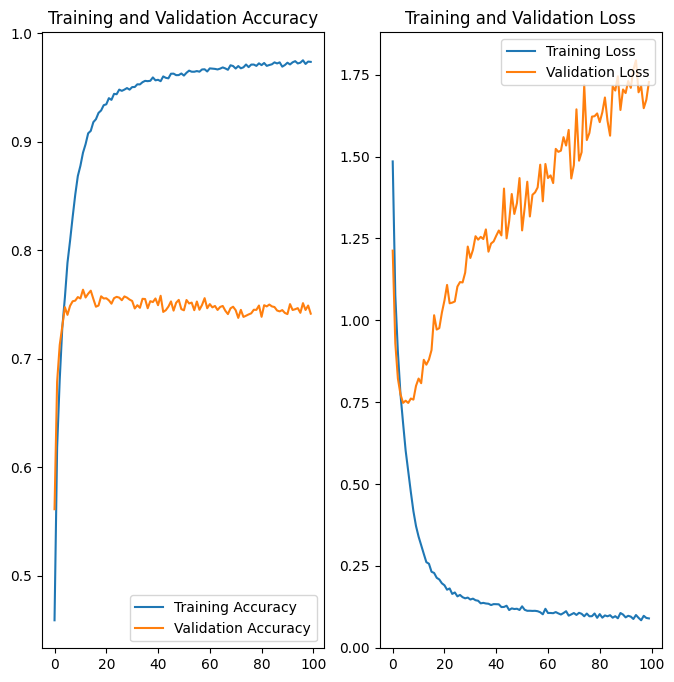

In [25]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(100
                     )

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()